# Auditoría monetaria acumulativa: expectativas y delegación

## Resumen ciclo30
Extensión ejecutada: q*=0,308571 reduce pérdida social de1,25 a0,867406; 144casos exactos y control negativo k0. Fórmulas, derivación, unidades y tradeoff en secciónCiclo30 al final. Se conserva la lección29.

Ancla sintética: compromisoL0,75, discreciónL1,25. Una política ingenua pareceL0,5, pero supone expectativas0 y genera inflación media0,5: no es un equilibrio de expectativas racionales. 54casos con dos estados equiprobables exactos; sin Monte Carlo ni datos reales. S2 local.

## Tres ideas y selección
Se compararon HAC para IV, extensión dinámica de bienes públicos e inconsistencia temporal monetaria. Se eligió la tercera para rotar de modelos recientes y auditar factibilidad de expectativas antes de ordenar objetivos. Teoría clásica; contribución incremental al repositorio, no prioridad científica.

## Modelo y secuencia

$y=\alpha(\pi-\pi^e)+\epsilon$, pérdida $L=\frac12[\pi^2+\lambda(y-k)^2]$. El privado fija $\pi^e$ antes del shock; el banco observa ε y elige π. Bajo discreción el privado anticipa esa mejor respuesta. Bajo compromiso se asume capacidad **costless y creíble** de fijar una regla contingente antes de expectativas; no se implementa un mecanismo institucional que la garantice.

Shock ε∈{−σ,+σ}, probabilidad0,5. Cuando σ0 son dos registros idénticos con peso0,5, no dos observaciones independientes. Variables normalizadas, no tasas calibradas o previsiones macro reales.

In [1]:
import json,csv
from pathlib import Path
import numpy as np
from IPython.display import display,Image
from src.monetary import policies,loss,best_response,oracle
root=Path.cwd()
r=json.loads((root/"results/summary.json").read_text())
print(json.dumps(r["config"],indent=2))

{
  "seed": 20261029,
  "alpha_values": [
    0.5,
    1,
    1.5
  ],
  "weight_values": [
    0.5,
    1,
    2
  ],
  "target_values": [
    0,
    0.5,
    1
  ],
  "shock_scales": [
    0,
    1
  ],
  "anchor": {
    "alpha": 1,
    "weight": 1,
    "target": 1,
    "shock_scale": 1
  },
  "hypothesis": "On54 exact two-state cases: RE residual commitment/discretion<=1e-12; loss gap=0.5*(weight*alpha*target)^2; scalar best-response oracle discrepancy<=1e-6. Anchor naive loss appears lower but RE residual>0, so reject as equilibrium comparison."
}


## Derivación y expectativas racionales

Mejor respuesta condicional: $\pi^{BR}=\lambda\alpha(\alpha\pi^e+k-\epsilon)/(1+\lambda\alpha^2)$. Bajo RE $\pi^e=E\pi=\lambda\alpha k=b$. Por tanto $\pi_D=b-\lambda\alpha\epsilon/(1+\lambda\alpha^2)$.

Compromiso óptimo dentro de reglas afines: $\pi_C=-\lambda\alpha\epsilon/(1+\lambda\alpha^2)$ y esperanza0. Ambas generan $y=\epsilon/(1+\lambda\alpha^2)$; la diferencia exacta de pérdida esperada es $\frac12b^2$. Bajo compromiso se impide reoptimizar ex post: no se verifica la misma mejor respuesta que discreción. La ventaja depende de esa capacidad asumida.

In [2]:
for shock in [-1,1]:
 for name,(pi,e) in policies(shock,1,1,1).items():
  print("Shock",shock,name,"π",pi,"πe",e,"y",pi-e+shock,"L",loss(pi,e,shock,1,1,1))
 print("Oráculo BR discreción",oracle(1,shock,1,1,1))

Shock -1 commitment π 0.5 πe 0.0 y -0.5 L 1.25
Shock -1 discretion π 1.5 πe 1 y -0.5 L 2.25
Shock -1 naive_fixed_expectations π 1.0 πe 0.0 y 0.0 L 1.0
Oráculo BR discreción 1.4999999999597544
Shock 1 commitment π -0.5 πe 0.0 y 0.5 L 0.25
Shock 1 discretion π 0.5 πe 1 y 0.5 L 0.25
Shock 1 naive_fixed_expectations π 0.0 πe 0.0 y 1.0 L 0.0
Oráculo BR discreción 0.5000000049247174


## Datos, baseline y control de admisibilidad
54escenarios de parámetros,3regímenes y2estados producen324registros. Discreción es baselineREfactible. La política ingenua congelaπe0 y usaBR: no debe contarse como régimen factible cuandoEπ≠πe. El oráculo escalar verifica la BRcondicional, no prueba compromiso institucional o causalidad.

In [3]:
rows=list(csv.DictReader((root/"results/cases.csv").open()))
assert len(rows)==54
print("Ancla",r["anchor"])
print("Error identidad de pérdida",r["max_loss_gap_identity_error"])
print("Error máximo BR versus oráculo",r["max_best_response_oracle_error"])
assert r["max_loss_gap_identity_error"]<1e-10
assert r["max_best_response_oracle_error"]<1e-6
for row in rows:
 assert float(row["commitment_re_residual"])<1e-12
 assert float(row["discretion_re_residual"])<1e-12

Ancla {'alpha': 1, 'weight': 1, 'target': 1, 'shock_scale': 1, 'commitment_loss': 0.75, 'discretion_loss': 1.25, 'naive_loss_inconsistent': 0.5, 'commitment_re_residual': 0.0, 'discretion_re_residual': 0.0, 'naive_re_residual': 0.5, 'commitment_mean_output': 0.0, 'discretion_mean_output': 0.0, 'naive_mean_output': 0.5, 'loss_gap_identity_error': 0.0, 'max_best_response_oracle_error': 4.92471741164735e-09}
Error identidad de pérdida 4.440892098500626e-16
Error máximo BR versus oráculo 1.4187990338143663e-08


## Falsación: menor pérdida aparente con equilibrio incumplido
Ancla: naiveL0,5 es menor que compromiso0,75, pero su inflación media0,5 contradiceexpectativa0. Su ganancia media de producto0,5 es sorpresa no anticipada, no un efecto sistemáticoRE. En los dos regímenes consistentes producto medio0. No recomendar una política por su objetivo si incumple restricciones.

In [4]:
a=r["anchor"]
assert a["naive_loss_inconsistent"]<a["commitment_loss"]
assert a["naive_re_residual"]>.4
assert abs(a["commitment_mean_output"])<1e-12
assert abs(a["discretion_mean_output"])<1e-12
print("Naive rechazada como equilibrio; no se cuenta su pérdida como mejora factible.")

Naive rechazada como equilibrio; no se cuenta su pérdida como mejora factible.


## Sensibilidad y control negativo
Cuando k0 desaparece la razón de sesgo: compromiso y discreción coinciden. Las diferencias aquí son exactas bajo el modelo, no errores estadísticos o evidencia de dominancia de reglas rígidas en modelos más amplios.

Control k0 confirmado.


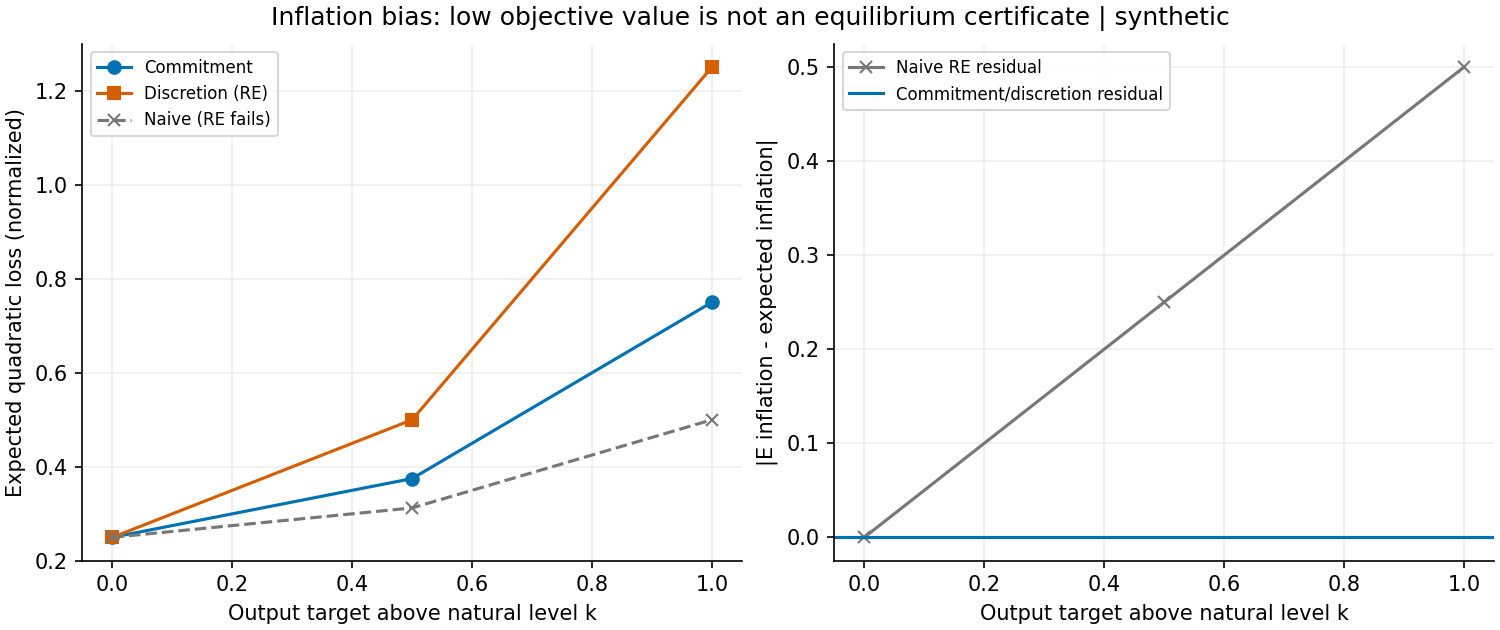

In [5]:
display(Image(filename=str(root/"results/comparison.png")))
for shock in [-1,1]:
 p=policies(shock,1,1,0)
 assert p["commitment"]==p["discretion"]
print("Control k0 confirmado.")

## Coste, trazabilidad y límites
Evaluación de54casos y oráculos escalares medida en tiempo/picoPython, noRSS ni latencia operacional. Sin benchmark de alta dimensión. No agentes heterogéneos, tipo de cambio, dinero, tasa de interés, credibilidad endógena, reputación repetida o estimación de parámetros.

In [6]:
print("Versiones",r["versions"])
print("Segundos instrumentados",r["seconds"],"PicoPython",r["python_peak_bytes"])
print("SHA256 datos",r["data_sha256"])
print("SHA256 núcleo",r["source_sha256"])

Versiones {'python': '3.12.14', 'numpy': '2.3.5', 'scipy': '1.17.0', 'matplotlib': '3.10.8'}
Segundos instrumentados 0.19710965999996688 PicoPython 233702
SHA256 datos fa0ad551a68ad9a3d0064770b8e4bd78ec09182bf3c59911be5547e3cfddf875
SHA256 núcleo 9d40bd8060f0d97f6dc49cdc23e3c29eef32455d1f548d54e6bd74c4e7bfd971


## Preguntas y siguientes pasos
¿Quién garantiza la regla comprometida? ¿Cómo cambian resultados si k depende de distorsiones o expectativas se aprenden? ¿Qué datos identifican α? No se responde con una recomendación para un banco real. Cinco referencias verificadas y un informe14p delimitan alcance.

Ejecución secuencial IPython limpio en proceso sin kernel/socket; errores abortan, outputs persisten; figura inspeccionada sin probar todos los frontends.

# Ciclo30: delegación conservadora como extensión acumulativa

El ciclo29 identifica la ventaja de compromiso **asumido**. Ahora mantenemos discreción y expectativas racionales y preguntamos qué peso delegado reduce la pérdida **social**. No mezclamos objetivos: λ pertenece a la sociedad, q al banquero. Es una ilustración clásica de Rogoff, no una teoría nueva. Tres candidatos: aprendizaje adaptativo (cambia RE), reputación repetida (demasiado alcance), delegación estática (seleccionada: reutiliza política y pérdida previas y aísla tradeoff).

## Fórmula original y modificación

Antes, banco y sociedad compartían $L_\lambda=\frac12[\pi^2+\lambda(y-k)^2]$. Propuesta implementada: banco minimiza $L_q$ mientras todas las comparaciones conservan $L_\lambda$. Con el mismo orden temporal y $E\epsilon=0$, $\pi^e=q\alpha k$, $\pi=q\alpha k-q\alpha\epsilon/(1+q\alpha^2)$, $y=\epsilon/(1+q\alpha^2)$.

Por expansión de cuadrados, $J(q)=E L_\lambda=\frac12[(q\alpha k)^2+\lambda k^2+\sigma^2((q\alpha)^2+\lambda)/(1+q\alpha^2)^2]$. Las variables son normalizadas: π,y,k,ε en unidades del modelo; α convierte sorpresa de inflación en producto; λ y q convierten cuadrados de producto en pérdida de inflación. No son puntos porcentuales calibrados.

## Derivación de la regla y unicidad

$J'(q)=\alpha^2[q k^2+\sigma^2(q-\lambda)/(1+\alpha^2q)^3]$. Multiplicar por el factor positivo da $F(q)=q k^2(1+\alpha^2q)^3+\sigma^2(q-\lambda)$. En $[0,\lambda]$, $F'(q)=k^2(1+\alpha^2q)^2(1+4\alpha^2q)+\sigma^2>0$ salvo degeneración k=σ=0; F(0)≤0 y F(λ)≥0. Existe raíz única y minimiza J globalmente para q≥0: fuera de λ la derivada es positiva. En degeneración toda q es equivalente y elegimos baselineλ. No se requiere convexidad global de J. Supuesto indispensable: nombramiento creíble y sin coste; su implementación política no se modela.

In [7]:
from src.delegation import optimal_weight,social_loss,state_average
d=json.loads((root/"results/delegation-summary.json").read_text())
print("Casos",d["cases"],"Ancla",d["anchor"])
q=optimal_weight(1,1,1,1)
print("q óptimo",q,"J social",social_loss(q,1,1,1,1))
assert abs(social_loss(q,1,1,1,1)-state_average(q,1,1,1,1))<1e-12

Casos 144 Ancla {'alpha': 1, 'weight': 1, 'target': 1, 'sigma': 1, 'q': 0.3085712007847549, 'baseline': 1.25, 'optimal': 0.8674056499645886, 'zero_weight': 1.0, 'oracle_loss_error': 0.0, 'state_error': 0.0}
q óptimo 0.3085712007847549 J social 0.8674056499645886


## Mecanismo, controles negativos y sensibilidad
Reducir q reduce sesgo, pero debilita estabilización. El criterio de éxito es J(q*)≤J(λ)+1e−10 en toda la malla, fórmula/estados y oráculo independientes coinciden a1e−10. La política extrema q0 falla cuando k0 y σ>0: elimina un sesgo que no existe y pierde estabilización. Si σ0,k>0 sí conviene q0. Nunca evaluamos al delegado con su propio objetivo para afirmar una ganancia social.

Error oráculo 3.552713678800501e-15 Error estados 4.440892098500626e-15
Negativo k0: q0 0.5 baseline 0.25


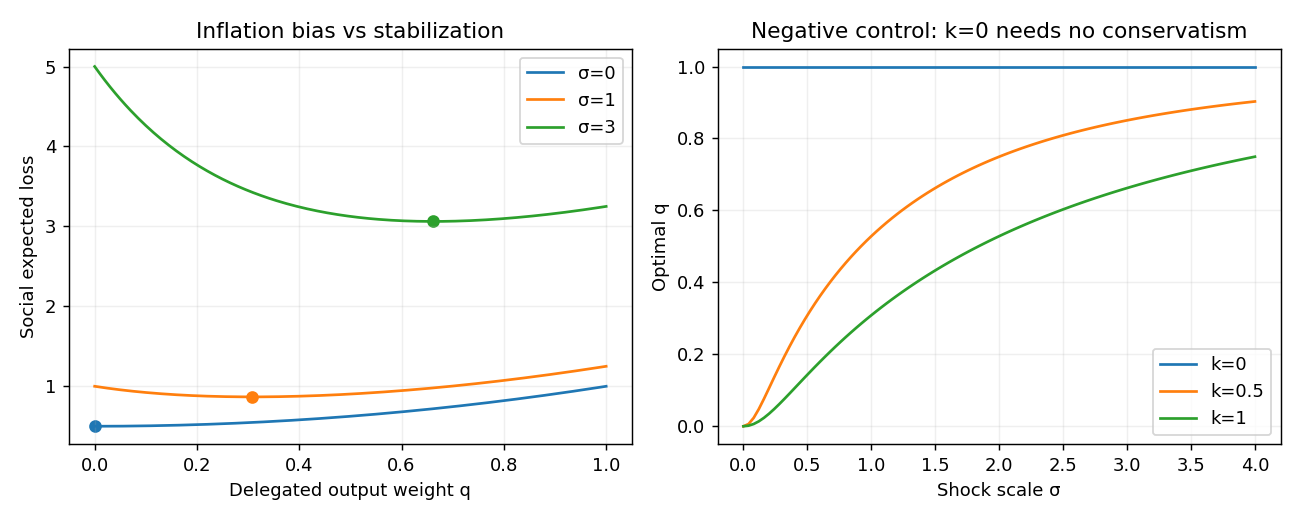

In [8]:
print("Error oráculo",d["max_oracle_loss_error"],"Error estados",d["max_state_error"])
assert optimal_weight(1,1,0,1)==1
assert social_loss(0,1,1,0,1)>social_loss(1,1,1,0,1)
assert optimal_weight(1,1,1,0)==0
print("Negativo k0: q0",social_loss(0,1,1,0,1),"baseline",social_loss(1,1,1,0,1))
display(Image(filename=str(root/"results/delegation.png")))

## Evidencia y clasificación honesta
144 casos exactos, sin muestreo ni inferencia empírica. Aporte: extensión computacional acumulativa y educativa del repositorio; fórmula deriva una especialización lineal-cuadrática de mecanismo clásico. No innovación teórica ni garantía de política real. No multilenguaje añadido: duplicar solver escalar no aporta al objetivo. Tiempo y memoria Python instrumentados son coste del barrido, no RSS ni escalabilidad operacional. Ver informe.md14p, matriz de cinco referencias, research-log.md y roadmap del programa.